In [1]:
import glob
import numpy as np
import matplotlib.pyplot as plt
import dbetto
import lh5
import pandas as pd
import pygeomhades
import pygeomtools
from pygeomtools import write_pygeom
import pyg4ometry as pg4
from pyg4ometry import gdml
from pathlib import Path
from copy import deepcopy
from pathlib import Path


from scipy.optimize import least_squares
from scipy.special import erf, erfc, xlogy
from scipy.stats import exponnorm

%matplotlib inline


In [2]:
import numpy as np
import glob
import os, json
import matplotlib.pyplot as plt
import pygama.pargen.energy_cal as cal
import pygama.math.histogram as pgh
from pygama.pargen.utils import load_data
from pygama.pargen.data_cleaning import get_tcm_pulser_ids
import pygama.pargen.energy_cal as pgc
import pygama.math.distributions as pgf
from legendmeta import LegendMetadata
from dbetto import Props

import rich
import logging
logging.basicConfig(level=logging.INFO)

%matplotlib inline

# functions


In [7]:
version = "v1.2.1"
camoaign = 'c1'


def get_background_efb3(
    db,
    detector,
    campaign=campaign,
    version=version,
):
    config = db.hardware.configuration[detector][campaign]["bkg"]

    folder = Path(
        "/global/cfs/cdirs/m2676/data/teststands/hades/"
        f"prodenv/ref/{version}/generated/tier/hit/"
        f"{detector}/{campaign}/bkg"
    )

    backgrounds = {}

    for run in sorted(config.keys()):
        if not (
            run.startswith("run")
            and run[3:].isdigit()
        ):
            continue

        try:
            meta = config[run]

            card = (
                meta["daq_settings"]["flashcam"]
                ["card_interface"]
            )

            if card != "efb3":
                continue

            run_tag = f"r{int(run[3:]):03d}"

            files = sorted(folder.glob(
                f"char_data-{detector}-bkg-"
                f"{run_tag}-*-tier_hit.lh5"
            ))

            backgrounds[run] = {
                "metadata": meta,
                "files": [str(path) for path in files],
                "live_time_s": float(meta["run_live_time_in_s"]),
            }

            print(
                f"{detector}/bkg/{run} | "
                f"Card: {card} | "
                f"Live time: {backgrounds[run]['live_time_s']:g} s | "
                f"Files: {len(files)}"
            )

            if not files:
                print("  Warning: no physics files found.")

        except (KeyError, FileNotFoundError, TypeError, ValueError) as exc:
            print(f"Skipping {detector}/bkg/{run}: {exc}")

    if not backgrounds:
        print(f"{detector}: no background runs with card efb3.")

    return backgrounds[run], run

# Data

In [8]:
background_run_tag = 'r003'
# qui devo mttere il background che ha la stessa card interface perche rappresenta ka misura di static tble aassoociata. in questo caso abbiamo lo scanning table

In [143]:
detector = "V14673A"

#detector = "V08682B"
#version = "v1.1.0"

measure = "am_HS1_top_dlt"



In [144]:
metadata_path = "/global/u2/r/ritaferi/HADES_DATA/hades-metadata"
db = dbetto.TextDB(metadata_path)

In [145]:
backgrounds, run_key  = get_background_efb3(
    db,
    detector=detector,
    campaign=campaign,
    version=version,
)

V14673A/bkg/run0002 | Card: efb3 | Live time: 25200 s | Files: 42


In [146]:
file_background = backgrounds['files']


In [147]:
emin = 0
emax = 7000
nbins = 70000
bins = np.linspace(emin, emax, nbins + 1)


In [148]:
from pathlib import Path
import re

import lh5
import numpy as np


force_rebuild = False

# Lista dei file di background già selezionati.
file_names_bkg = sorted(str(path) for path in file_background)

if not file_names_bkg:
    raise FileNotFoundError("Nessun file di background selezionato.")

# Ricava il run dai nomi dei file.
background_runs = set()

for filename in file_names_bkg:
    match = re.fullmatch(
        rf"char_data-{re.escape(detector)}-bkg-r(\d+)-.+-tier_hit\.lh5",
        Path(filename).name,
    )

    if match is None:
        raise ValueError(
            f"File non coerente con il background di {detector}: "
            f"{filename}"
        )

    background_runs.add(int(match.group(1)))

if len(background_runs) != 1:
    raise ValueError("Seleziona un solo run di background.")

background_run_key = f"run{background_runs.pop():04d}"

spectrum_dir = (
    Path("raw_energy_spectrum")
    / version
    / campaign
    / detector
)

spectrum_dir.mkdir(parents=True, exist_ok=True)

background_path = spectrum_dir / (
    f"{detector}_bkg_{background_run_key}_spectrum.npz"
)

bins_bkg = np.linspace(emin, emax, nbins + 1)

rebuild = force_rebuild or not background_path.exists()

if not rebuild:
    print(f"Carico: {background_path}")

    with np.load(background_path, allow_pickle=False) as spectrum:
        counts_bkg = np.asarray(spectrum["counts"]).copy()
        saved_bins = np.asarray(spectrum["bins"]).copy()

    valid = (
        saved_bins.shape == bins_bkg.shape
        and np.allclose(
            saved_bins, bins_bkg, rtol=0, atol=1e-8
        )
        and counts_bkg.shape == (len(bins_bkg) - 1,)
        and np.isfinite(counts_bkg).all()
        and np.all(counts_bkg >= 0)
    )

    rebuild = not valid

    if rebuild:
        print("Istogramma incompatibile: rigenero.")

if rebuild:
    print(f"Creo: {background_path}")

    counts_bkg = np.zeros(
        len(bins_bkg) - 1,
        dtype=np.int64,
    )

    for index, filename in enumerate(file_names_bkg, start=1):
        print(f"  File {index}/{len(file_names_bkg)}")

        energy_bkg = lh5.read(
            "hit/cuspEmax_ctc_cal",
            filename,
        ).nda

        partial_counts, _ = np.histogram(
            energy_bkg,
            bins=bins_bkg,
        )

        counts_bkg += partial_counts
        del energy_bkg, partial_counts

    np.savez_compressed(
        background_path,
        counts=counts_bkg,
        bins=bins_bkg,
    )

time_bkg = float(
    db.hardware.configuration[detector][campaign]
    ["bkg"][background_run_key]["run_live_time_in_s"]
)

print(f"Background: {detector}/{background_run_key}")
print(f"Live time: {time_bkg:g} s")
print(f"Bin width: {bins_bkg[1] - bins_bkg[0]:g} keV")

Creo: raw_energy_spectrum/v1.2.1/c1/V14673A/V14673A_bkg_run0002_spectrum.npz
  File 1/42
  File 2/42
  File 3/42
  File 4/42
  File 5/42
  File 6/42
  File 7/42
  File 8/42
  File 9/42
  File 10/42
  File 11/42
  File 12/42
  File 13/42
  File 14/42
  File 15/42
  File 16/42
  File 17/42
  File 18/42
  File 19/42
  File 20/42
  File 21/42
  File 22/42
  File 23/42
  File 24/42
  File 25/42
  File 26/42
  File 27/42
  File 28/42
  File 29/42
  File 30/42
  File 31/42
  File 32/42
  File 33/42
  File 34/42
  File 35/42
  File 36/42
  File 37/42
  File 38/42
  File 39/42
  File 40/42
  File 41/42
  File 42/42
Background: V14673A/run0002
Live time: 25200 s
Bin width: 0.1 keV


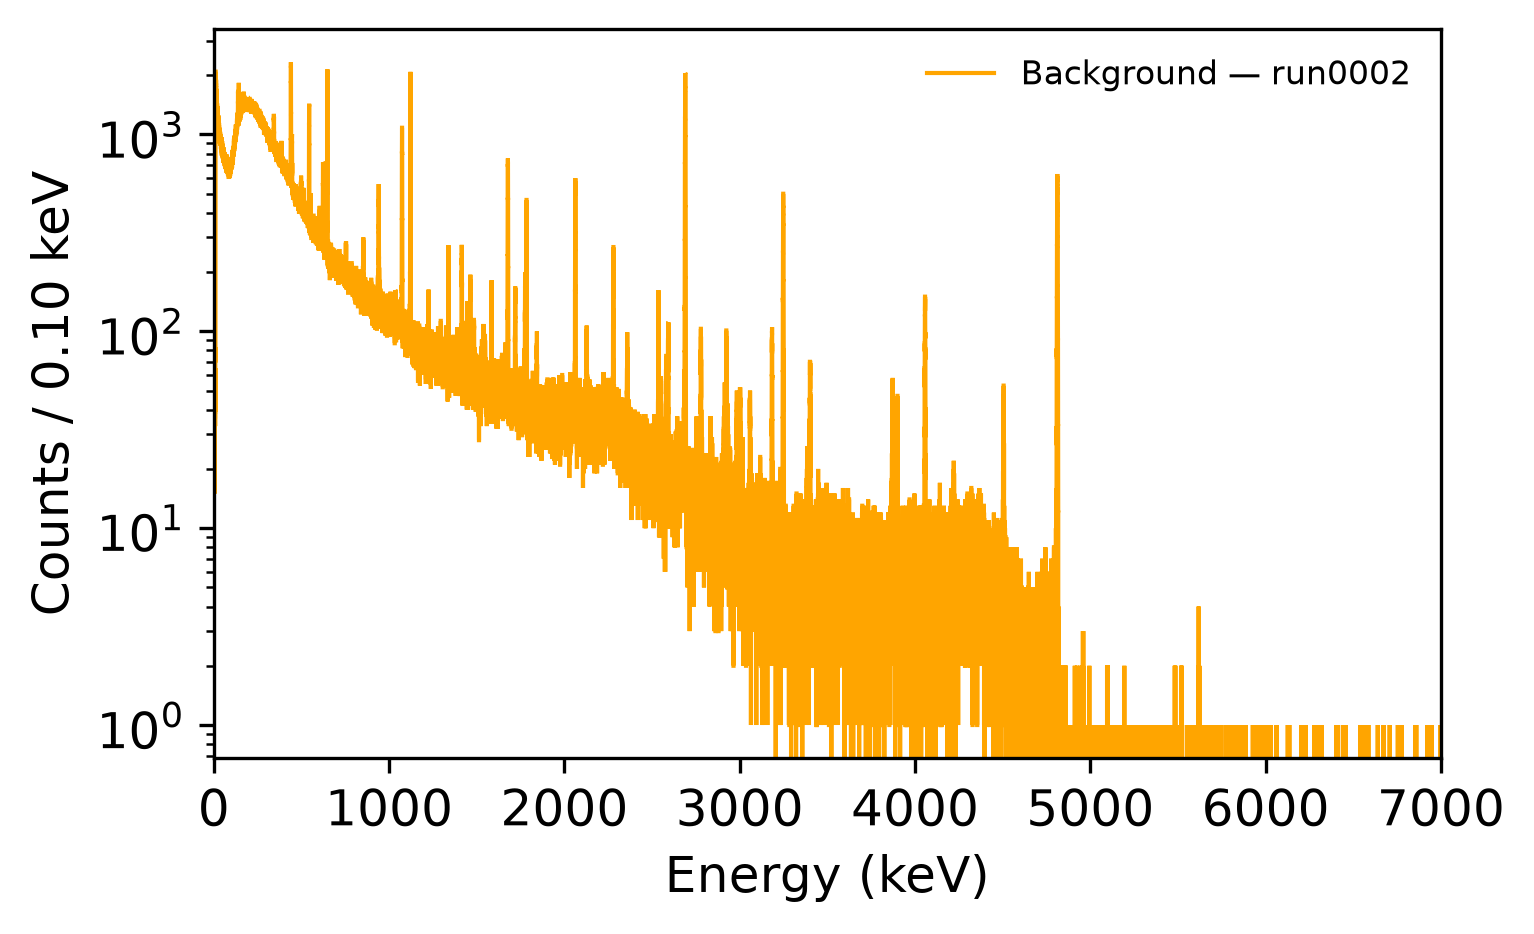

In [149]:

# ============================================================
# PLOT
# ============================================================

fig, ax = plt.subplots(
    figsize=(5, 3),
    dpi=300,
    layout="constrained",
)


ax.stairs(
    counts_bkg,
    bins,
    color="orange",
    label=f"Background — {run_key}",
)

ax.set_yscale("log")
ax.set_xlabel("Energy (keV)")
ax.set_ylabel(f"Counts / {bins[1] - bins[0]:.2f} keV")
ax.legend(frameon=False, fontsize=8)
ax.set_xlim(0, 7000)
#ax.set_xlim(52,62)
#ax.set_ylim(1e4, 1e6)
plt.show()

# calibration


In [150]:
e_uncal = lh5.read(
            "hit/cuspEmax_ctc_cal",
            filename,
        ).nda

e_uncal= e_uncal[(e_uncal<8000)]

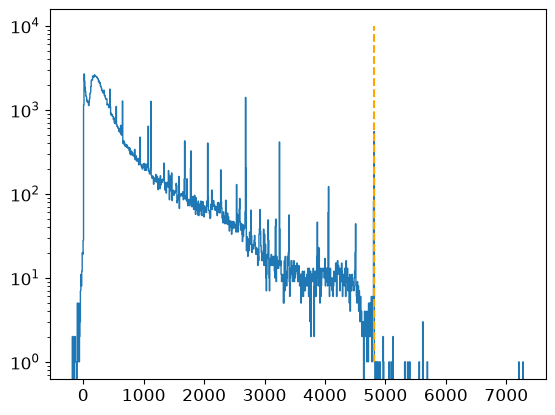

In [154]:
plt.figure()
plt.hist(e_uncal, bins=1000, histtype='step')
plt.yscale('log')
plt.vlines(np.nanpercentile(e_uncal, 99.9),1, 1e4, color = 'orange', ls = '--')
plt.show()

In [155]:
#help(pgc.HPGeCalibration)

INFO:pygama.pargen.energy_cal:4 peaks found:
INFO:pygama.pargen.energy_cal:	   Energy   | Position  
INFO:pygama.pargen.energy_cal:		0 583.191  | 1072.81
INFO:pygama.pargen.energy_cal:		1 727.33   | 1338.23
INFO:pygama.pargen.energy_cal:		2 1460.8   | 2688.06
INFO:pygama.pargen.energy_cal:		3 2614.5   | 4811.4
INFO:pygama.pargen.energy_cal:4 peaks obtained:
INFO:pygama.pargen.energy_cal:	   Energy   | Position  
INFO:pygama.pargen.energy_cal:		0 583.191  | 1073.03
INFO:pygama.pargen.energy_cal:		1 727.33   | 1338.06
INFO:pygama.pargen.energy_cal:		2 1460.8   | 2688.63
INFO:pygama.pargen.energy_cal:		3 2614.5   | 4810.74
INFO:pygama.pargen.energy_cal:4 peaks fitted:
INFO:pygama.pargen.energy_cal:	Energy: 583.191
INFO:pygama.pargen.energy_cal:		Parameter  |    Value +/- Sigma  
INFO:pygama.pargen.energy_cal:		x_lo       |  1036.23 +/- 10.36   
INFO:pygama.pargen.energy_cal:		x_hi       |  1109.83 +/- 11.10   
INFO:pygama.pargen.energy_cal:		n_sig      |   465.73 +/- 24.58   
INFO:pygama.

Coefficienti: [-0.09353844  0.54331109]


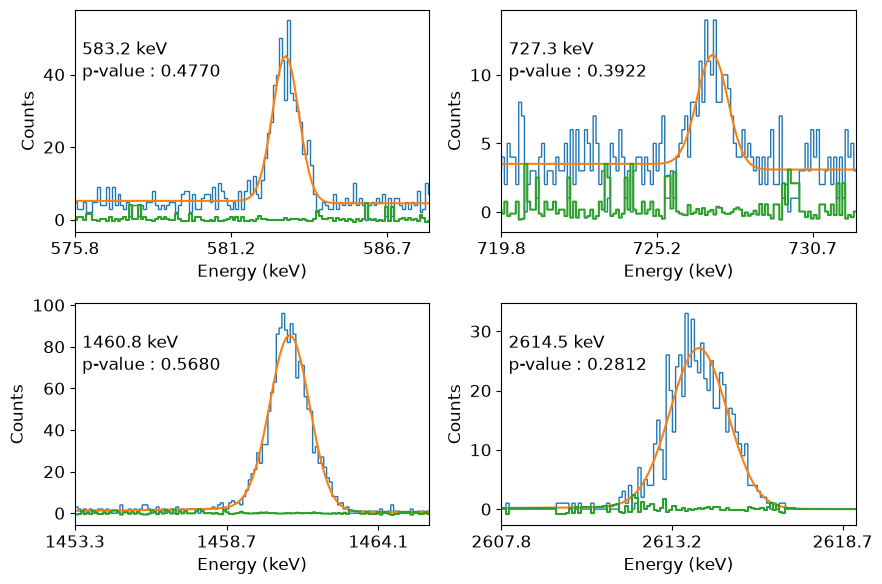

In [158]:
peak_pars_selected = [
    (583.191, (20, 20), pgf.hpge_peak),
    (727.330, (30, 30), pgf.hpge_peak),
    (1460.8,  (30, 30), pgf.hpge_peak),
    (2614.50, (60, 60), pgf.hpge_peak),
]

hpgecal = pgc.HPGeCalibration(
    "cuspEmax_ctc",  # deve corrispondere all'array e_uncal
    [entry[0] for entry in peak_pars_selected],
    guess_kev=guess_kev,
    deg=1,
    debug_mode=True,
)

hpgecal.hpge_find_energy_peaks(e_uncal)
hpgecal.hpge_get_energy_peaks(e_uncal)

hpgecal.hpge_fit_energy_peaks(
    e_uncal,
    peak_pars=peak_pars_selected,
)

print("Coefficienti:", hpgecal.pars)

fig = hpgecal.plot_fits(
    e_uncal,
    figsize=(9, 6),
    ncols=2,
    nrows=2,
)

display(fig)

In [159]:
from copy import deepcopy

fit_checks = {}

for energy, window, model in peak_pars:
    print(f"\n{'=' * 50}")
    print(
        f"Picco: {energy:g} keV | "
        f"finestra: {energy-window[0]:.2f}"
        f"–{energy+window[1]:.2f} keV",
        flush=True,
    )

    test_cal = deepcopy(hpgecal)
    test_cal.debug_mode = True

    try:
        test_cal.hpge_fit_energy_peaks(
            e_uncal,
            peak_pars=[(energy, window, model)],
            peaks_kev=[energy],
            update_cal_pars=False,
        )

        fit_checks[energy] = test_cal

        print(
            "Chiamata completata: controllare anche "
            "la validità del fit nei risultati.",
            flush=True,
        )

    except Exception as exc:
        print(
            f"FALLITO a {energy:g} keV:\n"
            f"{type(exc).__name__}: {exc}",
            flush=True,
        )


Picco: 583.191 keV | finestra: 563.19–603.19 keV


INFO:pygama.pargen.energy_cal:1 peaks fitted:
INFO:pygama.pargen.energy_cal:	Energy: 583.191
INFO:pygama.pargen.energy_cal:		Parameter  |    Value +/- Sigma  
INFO:pygama.pargen.energy_cal:		x_lo       |  1036.68 +/- 10.37   
INFO:pygama.pargen.energy_cal:		x_hi       |  1110.30 +/- 11.10   
INFO:pygama.pargen.energy_cal:		n_sig      |   465.75 +/- 22.65   
INFO:pygama.pargen.energy_cal:		mu         |  1073.56 +/- 0.64    
INFO:pygama.pargen.energy_cal:		sigma      |     0.84 +/- 0.06    
INFO:pygama.pargen.energy_cal:		htail      |     0.48 +/- 0.47    
INFO:pygama.pargen.energy_cal:		tau        |     0.15 +/- 0.15    
INFO:pygama.pargen.energy_cal:		n_bkg      |  1933.27 +/- 42.10   
INFO:pygama.pargen.energy_cal:		hstep      |    -0.06 +/- 0.02    


Chiamata completata: controllare anche la validità del fit nei risultati.

Picco: 727.33 keV | finestra: 697.33–757.33 keV


INFO:pygama.pargen.energy_cal:1 peaks fitted:
INFO:pygama.pargen.energy_cal:	Energy: 727.33
INFO:pygama.pargen.energy_cal:		Parameter  |    Value +/- Sigma  
INFO:pygama.pargen.energy_cal:		x_lo       |  1283.36 +/- 12.83   
INFO:pygama.pargen.energy_cal:		x_hi       |  1393.80 +/- 13.94   
INFO:pygama.pargen.energy_cal:		n_sig      |   110.01 +/- 10.47   
INFO:pygama.pargen.energy_cal:		mu         |  1338.63 +/- 1.56    
INFO:pygama.pargen.energy_cal:		sigma      |     0.99 +/- 0.16    
INFO:pygama.pargen.energy_cal:		htail      |     0.49 +/- 0.48    
INFO:pygama.pargen.energy_cal:		tau        |     0.10 +/- 0.16    
INFO:pygama.pargen.energy_cal:		n_bkg      |  1980.13 +/- 33.59   
INFO:pygama.pargen.energy_cal:		hstep      |    -0.07 +/- 0.02    


Chiamata completata: controllare anche la validità del fit nei risultati.

Picco: 860.564 keV | finestra: 830.56–890.56 keV


...

Chiamata completata: controllare anche la validità del fit nei risultati.

Picco: 2103.53 keV | finestra: 2063.53–2143.53 keV


/global/u2/r/ritaferi/HADES_DATA/.pixi/envs/default/lib/python3.12/site-packages/pygama/math/histogram.py:567: RuntimeWarning: divide by zero encountered in divide
  wts = None if var is None else 1 / np.sqrt(var[i_0:i_n])
INFO:pygama.pargen.energy_cal:0 peaks fitted:
ERROR:pygama.pargen.energy_cal:hpge_fit_energy_peaks: no peaks fitted


Chiamata completata: controllare anche la validità del fit nei risultati.

Picco: 2614.5 keV | finestra: 2554.50–2674.50 keV


INFO:pygama.pargen.energy_cal:1 peaks fitted:
INFO:pygama.pargen.energy_cal:	Energy: 2614.5
INFO:pygama.pargen.energy_cal:		Parameter  |    Value +/- Sigma  
INFO:pygama.pargen.energy_cal:		x_lo       |  4701.13 +/- 47.01   
INFO:pygama.pargen.energy_cal:		x_hi       |  4922.00 +/- 49.22   
INFO:pygama.pargen.energy_cal:		n_sig      |   632.54 +/- 25.50   
INFO:pygama.pargen.energy_cal:		mu         |  4811.58 +/- 0.07    
INFO:pygama.pargen.energy_cal:		sigma      |     1.67 +/- 0.05    
INFO:pygama.pargen.energy_cal:		htail      |     0.03 +/- 0.02    
INFO:pygama.pargen.energy_cal:		tau        |     6.73 +/- 3.76    
INFO:pygama.pargen.energy_cal:		n_bkg      |    56.44 +/- 8.60    
INFO:pygama.pargen.energy_cal:		hstep      |    -0.78 +/- 0.09    


Chiamata completata: controllare anche la validità del fit nei risultati.


Larghezza bin: 0.184057 unità non calibrate
Massimo conteggi/bin: 34
Eventi nella finestra: 641


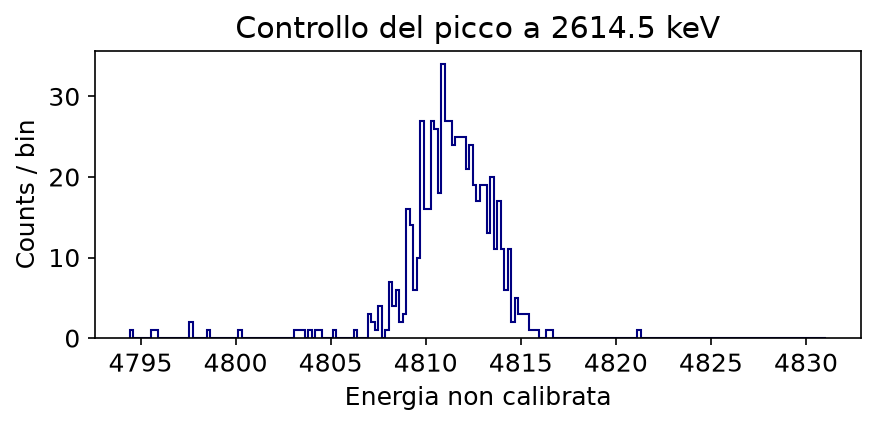

In [163]:
import numpy as np
import matplotlib.pyplot as plt

# Per calibrazione lineare: E = a + b*x.
slope = float(hpgecal.pars[1])

if slope <= 0:
    raise ValueError("Pendenza della calibrazione non positiva.")

# Centro del picco, ricavato dal fit che hai mostrato.
mu_uncal = np.nanpercentile(e_uncal, 99.9)

bin_width_uncal = 0.1 / slope

edges = np.arange(
    mu_uncal - 10 / slope,
    mu_uncal + 10 / slope,
    bin_width_uncal,
)

counts_check, edges = np.histogram(e_uncal, bins=edges)

print(f"Larghezza bin: {bin_width_uncal:.6g} unità non calibrate")
print("Massimo conteggi/bin:", counts_check.max())
print("Eventi nella finestra:", counts_check.sum())

fig, ax = plt.subplots(figsize=(6, 3), dpi=150)

ax.stairs(counts_check, edges, color="navy")
ax.set_xlabel("Energia non calibrata")
ax.set_ylabel("Counts / bin")
ax.set_title("Controllo del picco a 2614.5 keV")

plt.tight_layout()
plt.show()

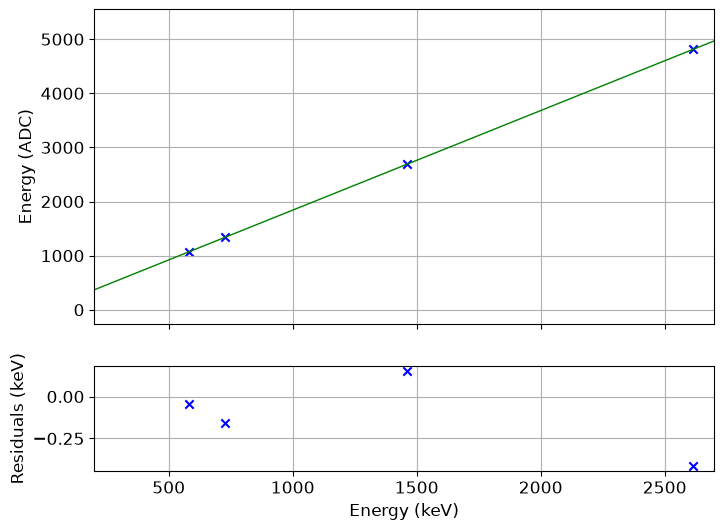

In [164]:
hpgecal.plot_cal_fit(e_uncal , figsize = [8,6] )

Object `ocis` not found.


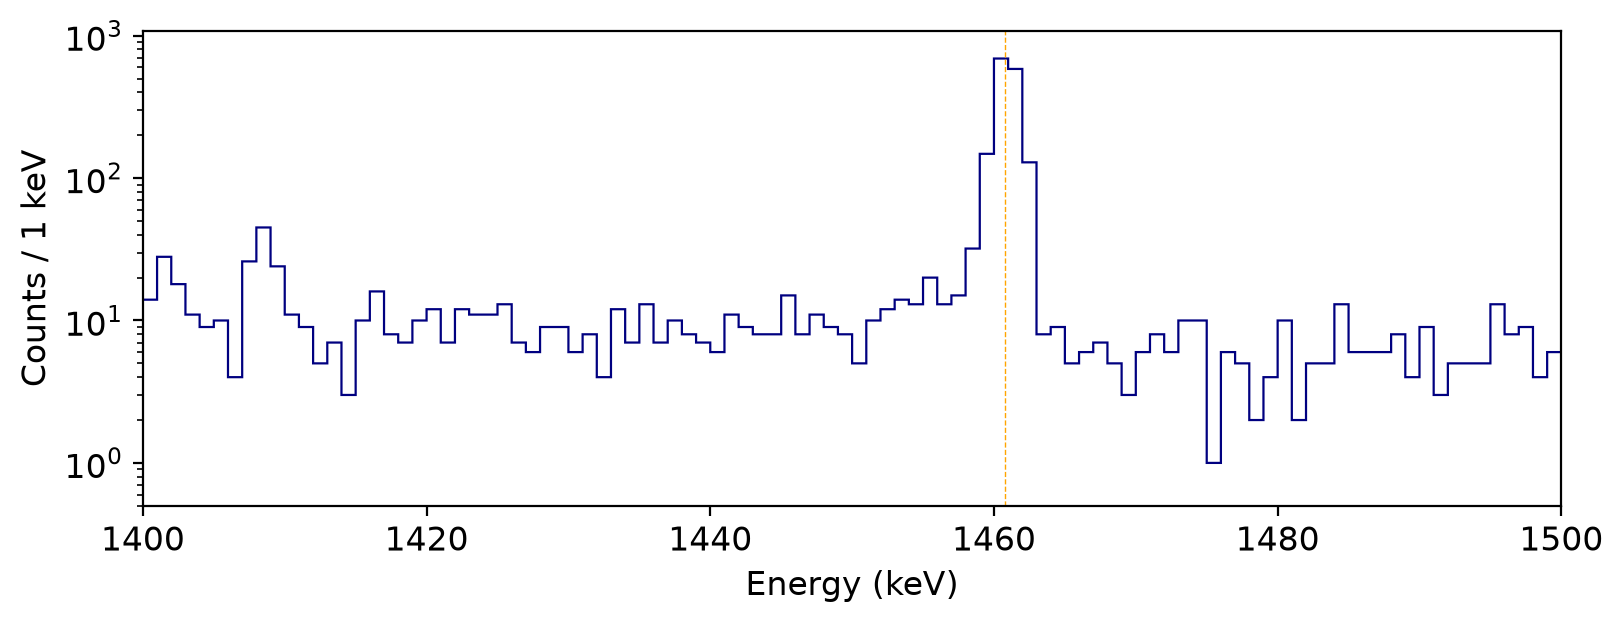

In [166]:
cal_peaks = [583.191,
                                727.330,
                                860.564,
             1460.8, 
                                1592.53,
                                1620.50,
                                2103.53,
                                2614.50]
# Con deg=1: energy_cal = a0 + a1 * e_uncal
energy_cal = np.polynomial.polynomial.polyval(
    np.asarray(e_uncal, dtype=float),
    hpgecal.pars,
)

energy_cal = energy_cal[np.isfinite(energy_cal)]

# Spettro calibrato: bin da 1 keV.
bins_cal = np.linspace(0, 3500, 3501)

counts_cal, bins_cal = np.histogram(
    energy_cal,
    bins=bins_cal,
)

fig, ax = plt.subplots(
    figsize=(8, 3),
    dpi=200,
    layout="constrained",
)

ax.stairs(
    counts_cal,
    bins_cal,
    color="navy",
    linewidth=0.8,
)
for cal in cal_peaks:
    ax.axvline(cal, color = 'orange', ls = '--', lw =  0.5)
ax.set_yscale("log")
ax.set_ylim(bottom=0.5)
ax.set_xlim(0, 3500)
ax.set_xlabel("Energy (keV)")
ax.set_ylabel("Counts / 1 keV")
ax.set_xlim(1400, 1500)
plt.show() posso usare ocis?